# Treasury Market Analytics — Executive Summary

End-to-end view of the five business questions this project set out to answer,
built directly on top of the `analytics/` modules and the `dbt` marts
(`fx_analytics_mart`, `yield_curve_mart`, `rate_differential_mart`). Every
number and chart below is computed live from `outputs/treasury.duckdb` — there
is no hardcoded data in this notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd().parent))

from analytics import fx_volatility, rate_fx_correlation, run_queries, yield_curve

CHARTS_DIR = Path("../outputs/charts")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette (see dataviz skill reference) — fixed hue
# order, never cycled. Status red is reserved for flagged/anomalous points.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
STATUS_CRITICAL = "#d03b3b"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
MUTED = "#898781"
INK = "#0b0b0b"

plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": AXIS,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
    }
)

DB_PATH = Path("../outputs/treasury.duckdb")
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"{DB_PATH} not found. Run `make ingest transform model` (or `make run`) "
        "and `dbt run` from dbt/treasury_dbt/ before this notebook."
    )

## Executive summary

Headline numbers pulled live from the marts, ahead of the detailed sections
below.

In [2]:
rate_diff = run_queries.run_query("usd_eur_differential_5y", db_path=DB_PATH)
inversions = yield_curve.build_inversion_report(db_path=DB_PATH)
correlations = rate_fx_correlation.build_correlation_report(db_path=DB_PATH)
vol_outliers = fx_volatility.build_volatility_report(db_path=DB_PATH)

latest_diff = rate_diff.dropna(subset=["usd_eur_differential"]).iloc[-1]
longest_inversion = inversions.loc[inversions["trading_days"].idxmax()]
usdbrl_level_corr = correlations.loc[
    (correlations["pair"] == "usd_policy_rate vs usdbrl_spot_rate")
    & (correlations["basis"] == "level"),
    "correlation",
].iloc[0]

fed_funds = latest_diff["usd_policy_rate"]
ecb_deposit = latest_diff["eur_policy_rate"]
summary = f"""
- **USD-EUR policy rate differential** (latest, {latest_diff["rate_date"].date()}):
  **{latest_diff["usd_eur_differential"]:+.2f} pp**
  (Fed Funds {fed_funds:.2f}% vs ECB Deposit {ecb_deposit:.2f}%)
- **Yield curve inversions detected:** {len(inversions)} — longest ran
  **{int(longest_inversion["trading_days"])} trading days**
  ({longest_inversion["start_date"].date()} to {longest_inversion["end_date"].date()})
- **Fed Funds vs USD/BRL correlation (level basis):** {usdbrl_level_corr:+.2f}
- **FX volatility outlier days flagged** (|z-score| >= 3, all series): {len(vol_outliers)}
"""
display(Markdown(summary))


- **USD-EUR policy rate differential** (latest, 2026-09-01):
  **+1.50 pp**
  (Fed Funds 3.75% vs ECB Deposit 2.25%)
- **Yield curve inversions detected:** 5 — longest ran
  **537 trading days**
  (2022-07-06 to 2024-08-26)
- **Fed Funds vs USD/BRL correlation (level basis):** +0.39
- **FX volatility outlier days flagged** (|z-score| >= 3, all series): 73


## 1. USD vs EUR policy rate differential (last 5 years)

*Business question: como evoluiu o diferencial de taxas USD vs EUR nos
últimos 5 anos?*

Fed Funds Rate vs ECB Deposit Facility Rate — the only two overnight policy
rates ingested with a comparable tenor (`rate_differential_mart`). Both are
step functions between central bank meetings, so values are forward-filled
for the chart only (not for the underlying differential calculation).

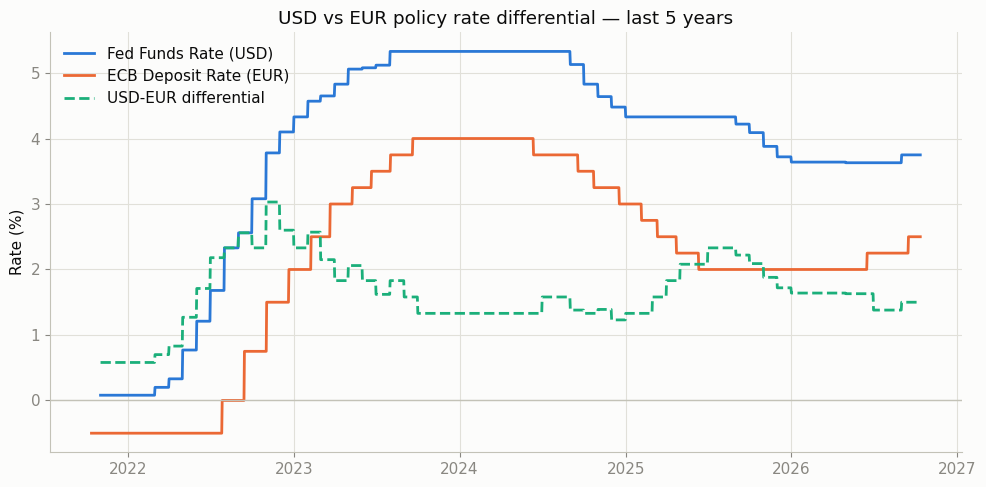

In [3]:
plot_df = rate_diff.set_index("rate_date")[
    ["usd_policy_rate", "eur_policy_rate", "usd_eur_differential"]
].ffill()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(plot_df.index, plot_df["usd_policy_rate"], color=BLUE, lw=2, label="Fed Funds Rate (USD)")
ax.plot(
    plot_df.index, plot_df["eur_policy_rate"], color=ORANGE, lw=2, label="ECB Deposit Rate (EUR)"
)
ax.plot(
    plot_df.index,
    plot_df["usd_eur_differential"],
    color=AQUA,
    lw=2,
    ls="--",
    label="USD-EUR differential",
)
ax.axhline(0, color=AXIS, lw=1)
ax.set_ylabel("Rate (%)")
ax.set_title("USD vs EUR policy rate differential — last 5 years")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_usd_eur_differential.png", dpi=150)
plt.show()

## 2. Yield curve inversions (US 2Y-10Y)

*Business question: quando ocorreram inversões da yield curve americana?
Quanto duraram?*

Shaded bands mark periods where `yield_10y < yield_2y` (`yield_curve_mart`).
Contiguity is measured in trading days, so weekends/holidays inside an
inversion don't split it into separate periods (see
`analytics/yield_curve.py::detect_inversions`).

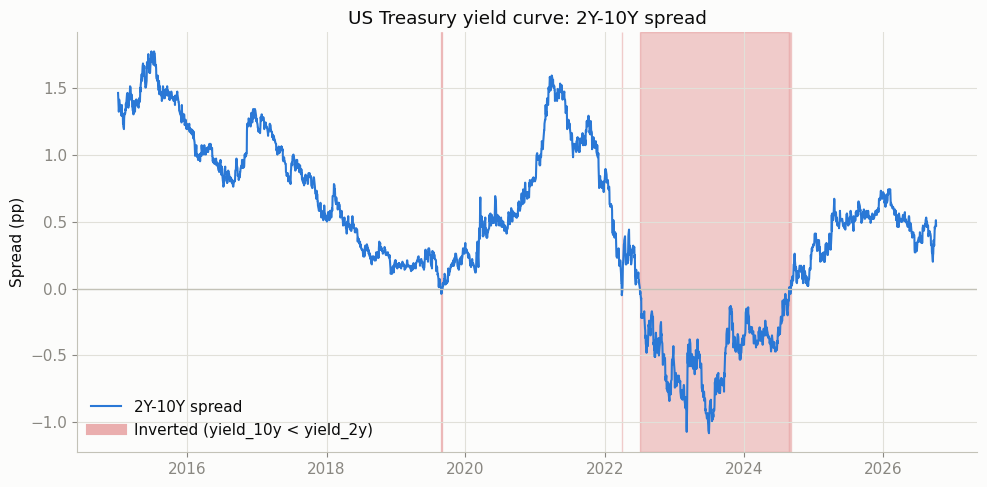

**Detected inversion periods:**

,Start,End,Calendar days,Trading days,Min spread (pp)
0,2019-08-27,2019-08-29,3,3,-0.04
1,2022-04-01,2022-04-04,4,2,-0.05
2,2022-07-06,2024-08-26,783,537,-1.08
3,2024-09-03,2024-09-03,1,1,-0.04
4,2024-09-05,2024-09-05,1,1,-0.02


In [4]:
curve = yield_curve.load_yield_curve(db_path=DB_PATH)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve["rate_date"], curve["spread_2y_10y"], color=BLUE, lw=1.5, label="2Y-10Y spread")
ax.axhline(0, color=AXIS, lw=1)
for _, period in inversions.iterrows():
    ax.axvspan(period["start_date"], period["end_date"], color=STATUS_CRITICAL, alpha=0.25)
ax.plot([], [], color=STATUS_CRITICAL, alpha=0.4, lw=8, label="Inverted (yield_10y < yield_2y)")
ax.set_ylabel("Spread (pp)")
ax.set_title("US Treasury yield curve: 2Y-10Y spread")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_yield_curve_inversions.png", dpi=150)
plt.show()

display(Markdown("**Detected inversion periods:**"))
display(
    inversions.rename(
        columns={
            "start_date": "Start",
            "end_date": "End",
            "duration_days": "Calendar days",
            "trading_days": "Trading days",
            "min_spread_2y_10y": "Min spread (pp)",
        }
    )
)

## 3. Fed Funds Rate vs USD/BRL

*Business question: qual a correlação entre o Fed Funds Rate e o USD/BRL?*

BRL has no policy rate series ingested, so this answers the question
directly against USD/BRL FX (`DEXBZUS`) rather than a BRL policy rate — see
`analytics/rate_fx_correlation.py`. Fed Funds and USD/BRL are plotted as two
stacked panels (not a dual-axis chart) since they're on unrelated scales.

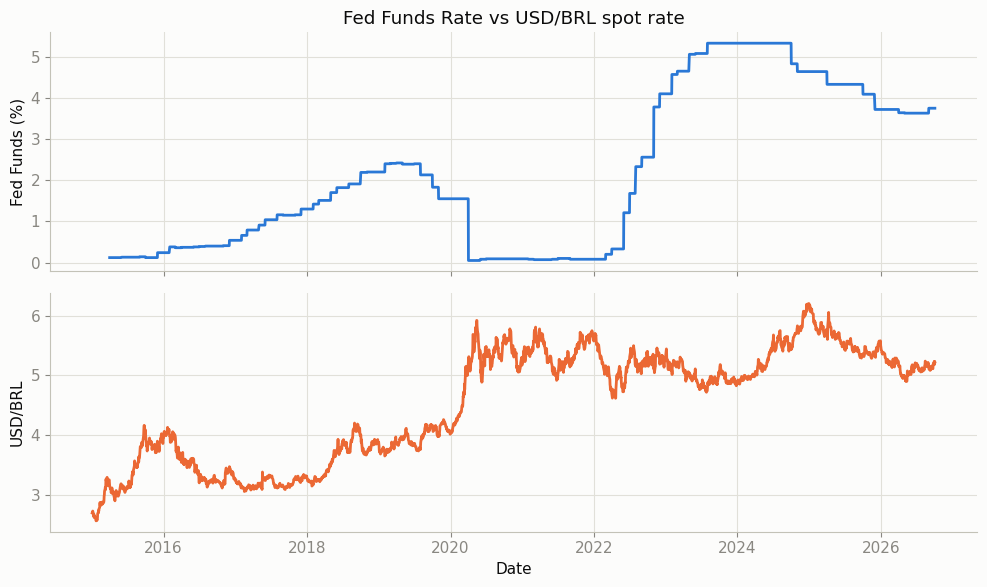

**Correlation summary (Pearson):**

,pair,basis,correlation,observations
0,usd_policy_rate vs usdbrl_spot_rate,level,0.387,91
1,usd_policy_rate vs usdbrl_spot_rate,change,-0.160,90
2,usd_eur_differential vs usdbrl_spot_rate,level,-0.006,91
3,usd_eur_differential vs usdbrl_spot_rate,change,-0.012,90


In [5]:
rate_fx = rate_fx_correlation.load_rate_fx(db_path=DB_PATH)
rate_fx_plot = rate_fx.set_index("rate_date")[["usd_policy_rate", "usdbrl_spot_rate"]].ffill()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(rate_fx_plot.index, rate_fx_plot["usd_policy_rate"], color=BLUE, lw=2)
ax1.set_ylabel("Fed Funds (%)")
ax1.set_title("Fed Funds Rate vs USD/BRL spot rate")

ax2.plot(rate_fx_plot.index, rate_fx_plot["usdbrl_spot_rate"], color=ORANGE, lw=2)
ax2.set_ylabel("USD/BRL")
ax2.set_xlabel("Date")

fig.tight_layout()
fig.savefig(CHARTS_DIR / "03_fedfunds_vs_usdbrl.png", dpi=150)
plt.show()

display(Markdown("**Correlation summary (Pearson):**"))
display(correlations.round(3))

## 4. FX volatility: EUR/USD vs USD/BRL

*Business question: qual a volatilidade histórica do EUR/USD vs USD/BRL?*

30-day rolling volatility of daily returns (`fx_analytics_mart`), with days
flagged as outliers (|z-score| >= 3 vs each series' own trailing 30-day mean
and volatility) marked on top — see `analytics/fx_volatility.py`.

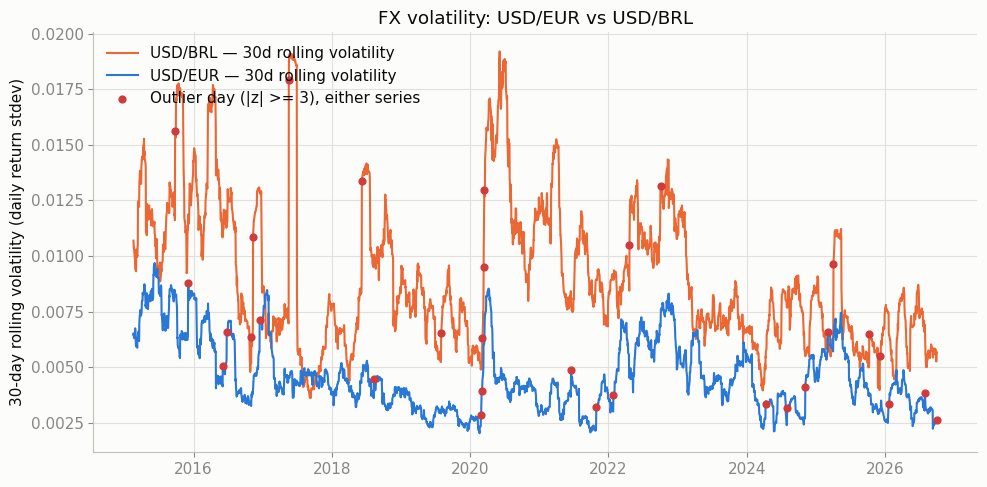

**Volatility summary:**

,series_id,observations,avg_volatility_30d,min_volatility_30d,max_volatility_30d
0,DEXBZUS,2908,0.0091,0.0036,0.0192
1,DEXUSEU,2908,0.0046,0.0020,0.0097


In [6]:
fx = fx_volatility.load_fx_analytics(db_path=DB_PATH)
fx_pairs = fx[fx["series_id"].isin(["DEXUSEU", "DEXBZUS"])]
outlier_pairs = vol_outliers[vol_outliers["series_id"].isin(["DEXUSEU", "DEXBZUS"])]

fig, ax = plt.subplots(figsize=(10, 5))
colors = {"DEXUSEU": BLUE, "DEXBZUS": ORANGE}
labels = {"DEXUSEU": "USD/EUR", "DEXBZUS": "USD/BRL"}
for series_id, group in fx_pairs.groupby("series_id"):
    ax.plot(
        group["rate_date"],
        group["rolling_volatility_30d"],
        color=colors[series_id],
        lw=1.5,
        label=f"{labels[series_id]} — 30d rolling volatility",
    )
ax.scatter(
    outlier_pairs["rate_date"],
    outlier_pairs["rolling_volatility_30d"],
    color=STATUS_CRITICAL,
    s=24,
    zorder=3,
    label="Outlier day (|z| >= 3), either series",
)
ax.set_ylabel("30-day rolling volatility (daily return stdev)")
ax.set_title("FX volatility: USD/EUR vs USD/BRL")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "04_fx_volatility.png", dpi=150)
plt.show()

display(Markdown("**Volatility summary:**"))
display(run_queries.run_query("fx_volatility_eur_usd_vs_usd_brl_summary", db_path=DB_PATH).round(4))

## Limitations

- **Business question #5** (comportamento das taxas pré/pós reuniões do
  FOMC) is deliberately out of scope — it needs a calendar of FOMC meeting
  dates, which isn't ingested anywhere in this project (see
  `analytics/queries.sql` and `PROJECT_NOTES.md`).
- `change_1d/1w/1m` in `fact_market_rates` assumes daily frequency; monthly
  series (`FEDFUNDS`, Euribor) are not yet adjusted for that — flagged in
  `PROJECT_NOTES.md` as a pending item.
- BIS OTC derivatives / FX turnover datasets are ingested but not yet wired
  into any staging/mart model, so they aren't part of this summary.